# Sistema Inteligente para la Predicción del Abandono de Clientes 
## Empresa hipotética de seguros de automóviles

**Objetivo:** estimar la probabilidad de que un cliente abandone la aseguradora (`abandono = 1`) o permanezca (`abandono = 0`), y convertir esa probabilidad en decisiones de negocio.


### Qué contiene? 
1. **XGBoost**
2. **Validación cruzada** de 5 grupos en lugar de un solo corte entrenamiento/prueba.
3. **Ajuste automático de parámetros** (RandomizedSearchCV).
4. **Calibración** de probabilidades.
5. **Umbral de decisión** elegido con **costos reales de negocio**.
6. **Importancia de variables** y explicación por cliente.

> Los datos son **simulados**.


## 1. Bibliotecas

In [1]:
%pip install -q xgboost openpyxl
import warnings; warnings.filterwarnings("ignore")
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns, joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             classification_report, ConfusionMatrixDisplay, RocCurveDisplay)
from xgboost import XGBClassifier

SEMILLA = 42
sns.set_theme(style="whitegrid")
print("Bibliotecas listas.")


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Bibliotecas listas.


## 2. Carga de datos
Se busca el archivo `Base_Datos_Simulada_Seguros_Auto.xlsx`. Si no está, se generan datos simulados equivalentes (3 000 clientes).

In [2]:
ARCHIVO = "Base_Datos_Simulada_Seguros_Auto.xlsx"

def generar_datos(n=3000):
    rng = np.random.default_rng(SEMILLA)
    edad = rng.integers(18, 76, n); antig = rng.integers(1, 16, n)
    cob = rng.choice(["Basica", "Intermedia", "Completa"], size=n, p=[0.30, 0.45, 0.25])
    prima = np.clip(rng.normal(55 + (cob == "Completa")*35 + (cob == "Intermedia")*15, 18, n), 20, 180).round(2)
    pagos = rng.poisson(0.7, n); acc = rng.poisson(0.45, n); recl = rng.poisson(0.55, n)
    sat = rng.integers(1, 6, n); cont = rng.poisson(1.4, n); renov = np.maximum(antig - 1, 0)
    z = (-2.15 + 0.48*pagos + 0.22*acc + 0.18*recl + 0.55*(5 - sat) + 0.16*cont
         + 0.012*(prima - 70) - 0.075*antig - 0.025*renov + 0.20*(cob == "Basica"))
    ab = rng.binomial(1, 1/(1 + np.exp(-z)))
    return pd.DataFrame(dict(edad=edad, antiguedad_anios=antig, tipo_cobertura=cob, prima_mensual=prima,
                             pagos_atrasados=pagos, accidentes=acc, reclamaciones=recl,
                             satisfaccion=sat, contactos_servicio=cont, renovaciones=renov, abandono=ab))

def leer_excel(ruta):
    bruto = pd.read_excel(ruta, sheet_name=0, header=None, dtype=str)
    fila = next(i for i in range(15) if "edad" in [str(c).strip().lower() for c in bruto.iloc[i]])
    df = bruto.iloc[fila+1:].copy()
    df.columns = [str(c).strip().lower().replace("ñ", "n") for c in bruto.iloc[fila]]
    df = df.dropna(how="all")
    for c in df.columns:
        if c != "tipo_cobertura":
            df[c] = pd.to_numeric(df[c], errors="coerce")
    return df.reset_index(drop=True)

if os.path.exists(ARCHIVO):
    df = leer_excel(ARCHIVO); print("Datos leídos desde el Excel.")
else:
    df = generar_datos(); print("No se encontró el Excel: se generaron datos simulados.")

print(df.shape, f"| abandono: {df['abandono'].mean():.1%}")
df.head()

Datos leídos desde el Excel.
(3000, 11) | abandono: 31.0%


,edad,antiguedad_anios,tipo_cobertura,prima_mensual,pagos_atrasados,accidentes,reclamaciones,satisfaccion,contactos_servicio,renovaciones,abandono
0,23,12,Completa,71.33,1,1,1,1,1,11,0
1,62,11,Intermedia,78.69,1,1,0,2,0,10,0
2,55,14,Basica,44.06,2,0,1,1,1,13,1
3,43,15,Intermedia,40.32,0,1,1,3,2,14,0
4,43,11,Basica,49.83,0,0,0,4,0,10,0


## 3. Exploración visual

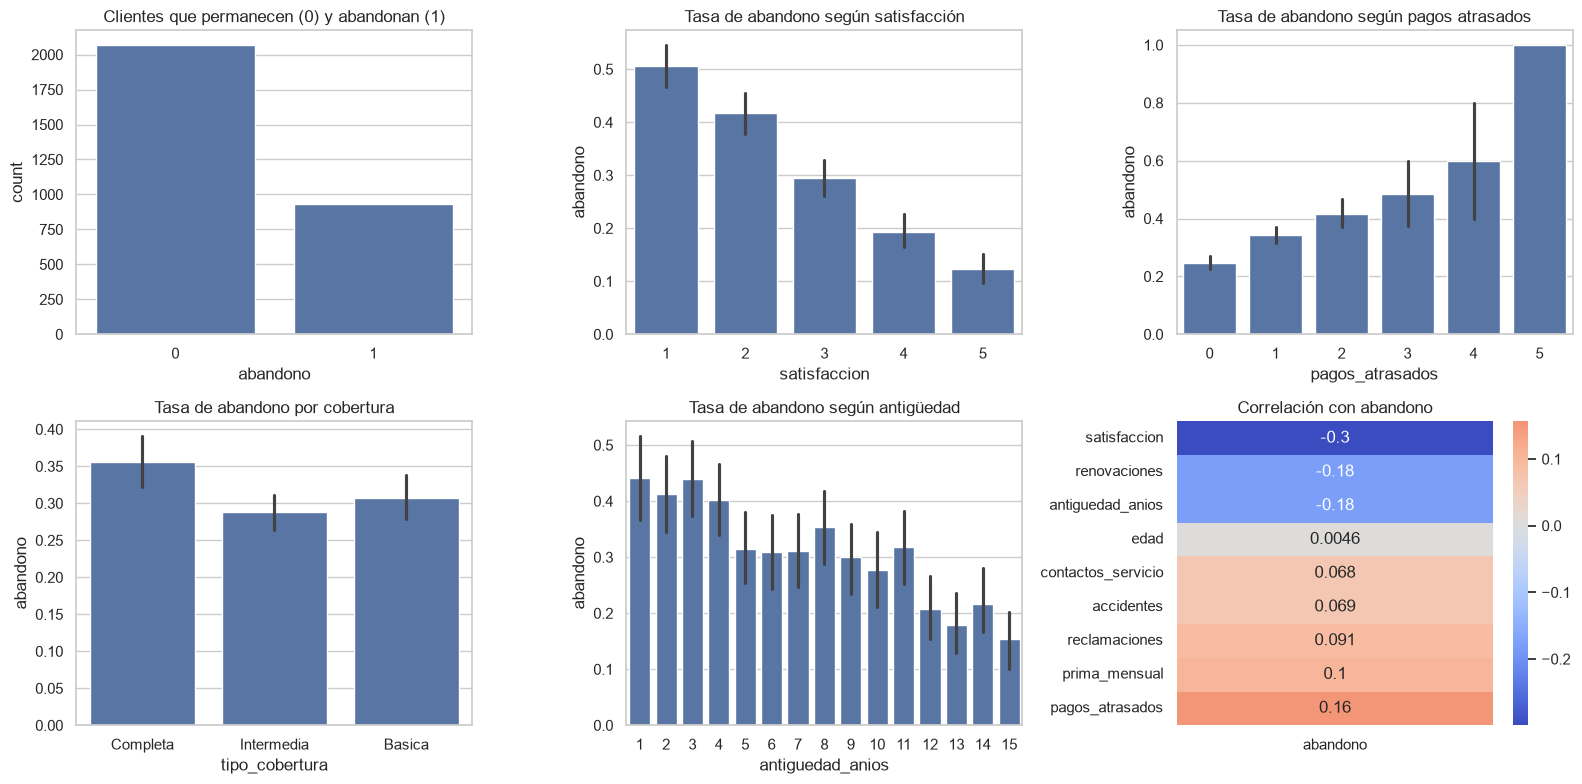

In [3]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
sns.countplot(data=df, x="abandono", ax=ax[0,0]); ax[0,0].set_title("Clientes que permanecen (0) y abandonan (1)")
sns.barplot(data=df, x="satisfaccion", y="abandono", ax=ax[0,1]); ax[0,1].set_title("Tasa de abandono según satisfacción")
sns.barplot(data=df, x="pagos_atrasados", y="abandono", ax=ax[0,2]); ax[0,2].set_title("Tasa de abandono según pagos atrasados")
sns.barplot(data=df, x="tipo_cobertura", y="abandono", ax=ax[1,0]); ax[1,0].set_title("Tasa de abandono por cobertura")
sns.barplot(data=df, x="antiguedad_anios", y="abandono", ax=ax[1,1]); ax[1,1].set_title("Tasa de abandono según antigüedad")
sns.heatmap(df.select_dtypes("number").corr()[["abandono"]].drop("abandono").sort_values("abandono"), annot=True, cmap="coolwarm", center=0, ax=ax[1,2])
ax[1,2].set_title("Correlación con abandono")
plt.tight_layout(); plt.show()

## 4. Preparación
Se separa el 20 % de los datos como **prueba final**, que no se toca hasta el final. El preprocesamiento va dentro de un `Pipeline` para que se aplique igual al entrenar y al predecir.

In [4]:
COLS_X = ["edad","antiguedad_anios","tipo_cobertura","prima_mensual","pagos_atrasados",
          "accidentes","reclamaciones","satisfaccion","contactos_servicio","renovaciones"]
COLS_CAT = ["tipo_cobertura"]
COLS_NUM = [c for c in COLS_X if c not in COLS_CAT]

df = df.dropna(subset=COLS_X + ["abandono"])
X, y = df[COLS_X], df["abandono"].astype(int)
X_ent, X_prueba, y_ent, y_prueba = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEMILLA)

def preprocesador():
    return ColumnTransformer([("num", StandardScaler(), COLS_NUM),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), COLS_CAT)])
print("Entrenamiento:", len(X_ent), "| Prueba final:", len(X_prueba))

Entrenamiento: 2400 | Prueba final: 600


## 5. Comparación de cuatro modelos con validación cruzada
La **validación cruzada** divide los datos de entrenamiento en 5 partes; entrena con 4 y evalúa con la 5ª, y repite 5 veces. El resultado es un promedio más confiable que un solo corte. La métrica es **ROC-AUC** (0.5 = azar, 1 = perfecto).

,Modelo,ROC-AUC promedio,Variación (±)
0,Regresión Logística,0.762,0.021
1,XGBoost,0.752,0.025
2,Random Forest,0.746,0.026
3,Árbol de Decisión,0.705,0.014


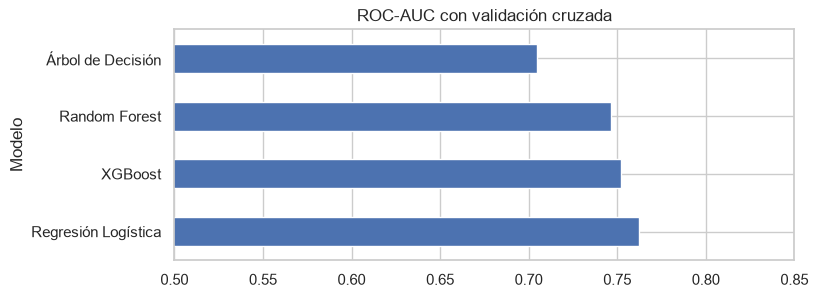

In [5]:
algoritmos = {
    "Regresión Logística": LogisticRegression(max_iter=2000),
    "Árbol de Decisión": DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=SEMILLA),
    "Random Forest": RandomForestClassifier(n_estimators=250, max_depth=8, min_samples_leaf=10, random_state=SEMILLA, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=150, max_depth=3, learning_rate=0.05, subsample=0.8,
                             colsample_bytree=0.8, eval_metric="logloss", random_state=SEMILLA),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)
filas = []
for nombre, alg in algoritmos.items():
    pipe = Pipeline([("pre", preprocesador()), ("m", alg)])
    s = cross_val_score(pipe, X_ent, y_ent, cv=cv, scoring="roc_auc")
    filas.append({"Modelo": nombre, "ROC-AUC promedio": s.mean(), "Variación (±)": s.std()})
tabla_cv = pd.DataFrame(filas).sort_values("ROC-AUC promedio", ascending=False).reset_index(drop=True)
display(tabla_cv.round(3))
tabla_cv.set_index("Modelo")["ROC-AUC promedio"].plot(kind="barh", xlim=(0.5, 0.85), figsize=(8, 3), title="ROC-AUC con validación cruzada")
plt.show()

**Cómo leer esta tabla:** si las diferencias son menores que la variación (±), los modelos son prácticamente equivalentes. Aquí los datos se crearon con una fórmula logística, por eso la Regresión Logística rinde tan bien. Con datos reales de una aseguradora, los modelos de árboles (Random Forest, XGBoost) suelen aportar más porque capturan relaciones no lineales.

## 6. Ajuste de parámetros de XGBoost
`RandomizedSearchCV` prueba combinaciones al azar de configuraciones y se queda con la mejor según validación cruzada.

In [6]:
busqueda = RandomizedSearchCV(
    Pipeline([("pre", preprocesador()), ("m", XGBClassifier(eval_metric="logloss", random_state=SEMILLA))]),
    param_distributions={
        "m__n_estimators": [100, 150, 250, 400],
        "m__max_depth": [2, 3, 4, 5],
        "m__learning_rate": [0.02, 0.05, 0.1],
        "m__subsample": [0.7, 0.85, 1.0],
        "m__colsample_bytree": [0.7, 0.85, 1.0],
        "m__min_child_weight": [1, 5, 10],
    },
    n_iter=15, scoring="roc_auc", cv=cv, random_state=SEMILLA, n_jobs=-1)
busqueda.fit(X_ent, y_ent)
print("Mejor ROC-AUC (validación cruzada):", round(busqueda.best_score_, 4))
print("Mejores parámetros:", busqueda.best_params_)

Mejor ROC-AUC (validación cruzada): 0.7558
Mejores parámetros: {'m__subsample': 0.85, 'm__n_estimators': 100, 'm__min_child_weight': 10, 'm__max_depth': 2, 'm__learning_rate': 0.1, 'm__colsample_bytree': 0.85}


## 7. Elección del modelo final y calibración
Se elige el modelo con mayor ROC-AUC entre las 4 opciones y el XGBoost ajustado. Después se **calibra**: así, cuando el modelo dice "70 %", de verdad ~7 de cada 10 clientes similares abandonan. Esto importa porque la probabilidad se usa para calcular dinero.

In [7]:
mejores = {r["Modelo"]: r["ROC-AUC promedio"] for _, r in tabla_cv.iterrows()}
mejores["XGBoost ajustado"] = busqueda.best_score_
nombre_final = max(mejores, key=mejores.get)
print("Modelo elegido:", nombre_final)

if nombre_final == "XGBoost ajustado":
    base = busqueda.best_estimator_
else:
    base = Pipeline([("pre", preprocesador()), ("m", algoritmos[nombre_final])])

modelo_final = CalibratedClassifierCV(base, cv=5, method="sigmoid").fit(X_ent, y_ent)

Modelo elegido: Regresión Logística


## 8. Evaluación final con datos que el modelo nunca vio

ROC-AUC en prueba final: 0.757
              precision    recall  f1-score   support

   Permanece       0.76      0.89      0.82       414
    Abandona       0.60      0.37      0.46       186

    accuracy                           0.73       600
   macro avg       0.68      0.63      0.64       600
weighted avg       0.71      0.73      0.71       600



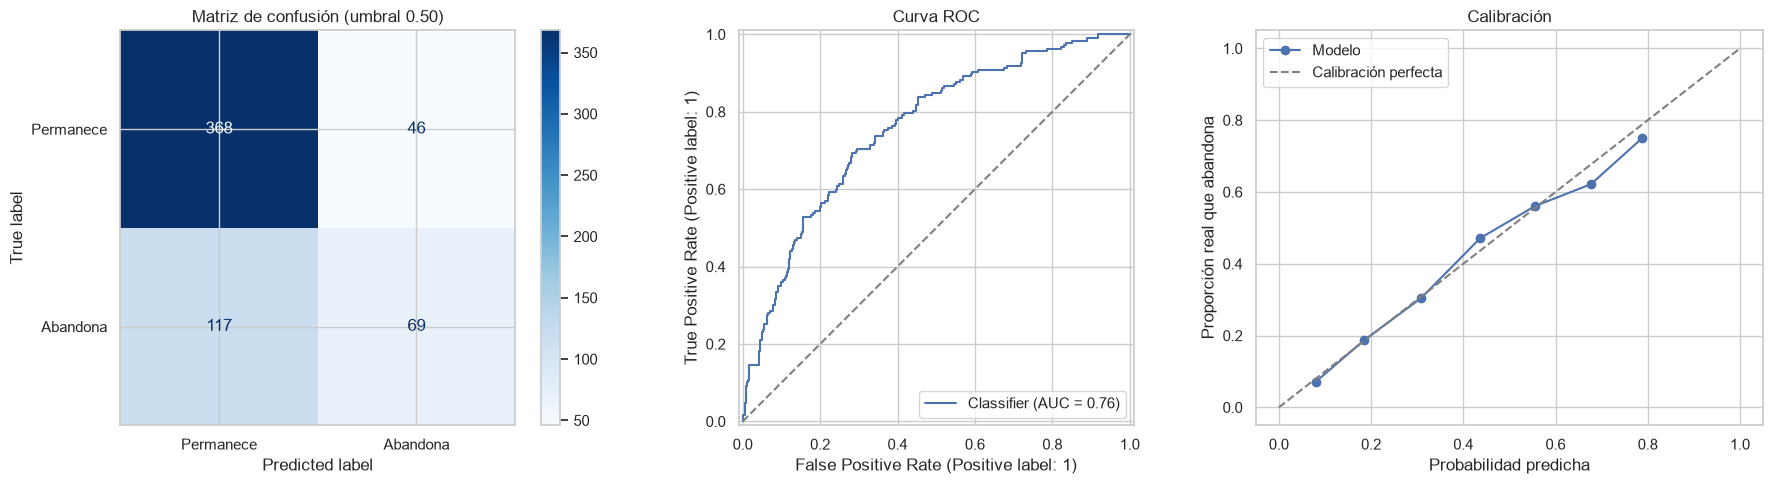

In [8]:
prob = modelo_final.predict_proba(X_prueba)[:, 1]
pred = (prob >= 0.50).astype(int)
print(f"ROC-AUC en prueba final: {roc_auc_score(y_prueba, prob):.3f}")
print(classification_report(y_prueba, pred, target_names=["Permanece", "Abandona"]))

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ConfusionMatrixDisplay.from_predictions(y_prueba, pred, display_labels=["Permanece","Abandona"], cmap="Blues", ax=ax[0])
ax[0].set_title("Matriz de confusión (umbral 0.50)")
RocCurveDisplay.from_predictions(y_prueba, prob, ax=ax[1]); ax[1].plot([0,1],[0,1],"--",color="gray"); ax[1].set_title("Curva ROC")
frac, medio = calibration_curve(y_prueba, prob, n_bins=8)
ax[2].plot(medio, frac, "o-", label="Modelo"); ax[2].plot([0,1],[0,1],"--",color="gray", label="Calibración perfecta")
ax[2].set_xlabel("Probabilidad predicha"); ax[2].set_ylabel("Proporción real que abandona"); ax[2].set_title("Calibración"); ax[2].legend()
plt.tight_layout(); plt.show()

## 9. Del modelo al negocio: ¿a quién contactar?
Para que el modelo sirva en una empresa, hay que decidir **a partir de qué probabilidad se llama al cliente**. Eso depende de dinero:

- **Costo de contacto:** lo que cuesta una llamada o un descuento.
- **Éxito de retención:** qué porcentaje de contactados se queda.
- **Valor del cliente:** aquí, la prima de 12 meses.

Modifica los supuestos y vuelve a ejecutar. Son valores de ejemplo, no datos reales.

Probabilidad mínima a partir de la cual conviene contactar (cliente típico): 36%
Umbral que maximiza el ahorro con estos supuestos: 0.35


,Umbral,Clientes contactados,Precisión,Recall,Ahorro neto (US$)
0,0.05,2344,0.318,1.000,-9123.432
1,0.10,2091,0.351,0.984,4071.720
2,0.15,1808,0.387,0.940,15649.464
3,0.20,1553,0.418,0.871,22572.936
4,0.25,1312,0.454,0.800,29093.280
5,0.30,1068,0.495,0.710,32545.752
6,0.35,894,0.526,0.631,32653.104
7,0.40,726,0.556,0.542,31025.136
8,0.45,566,0.597,0.454,29365.656
9,0.50,437,0.638,0.374,26052.384


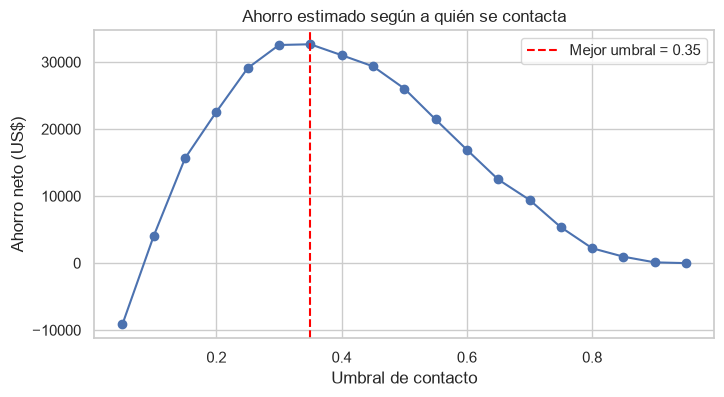

In [9]:
COSTO_CONTACTO = 60     # dólares por cliente contactado (llamada del asesor + incentivo)
EXITO_RETENCION = 0.20  # 20 % de los contactados que iban a irse se quedan

# Regla práctica: conviene contactar si  probabilidad × éxito × valor del cliente > costo de contacto.
valor_tipico = X_ent["prima_mensual"].mean() * 12
print(f"Probabilidad mínima a partir de la cual conviene contactar (cliente típico): {COSTO_CONTACTO / (EXITO_RETENCION * valor_tipico):.0%}")

# Probabilidades "fuera de muestra" para todo el conjunto de entrenamiento
prob_oof = cross_val_predict(CalibratedClassifierCV(base, cv=5, method="sigmoid"), X_ent, y_ent, cv=cv, method="predict_proba")[:, 1]
valor = X_ent["prima_mensual"].values * 12
real = y_ent.values

umbrales = np.arange(0.05, 0.96, 0.05)
filas = []
for u in umbrales:
    contactados = prob_oof >= u
    ahorro = (real[contactados] * EXITO_RETENCION * valor[contactados]).sum() - contactados.sum() * COSTO_CONTACTO
    tp = (contactados & (real == 1)).sum()
    filas.append({"Umbral": round(u, 2), "Clientes contactados": int(contactados.sum()),
                  "Precisión": tp / max(contactados.sum(), 1), "Recall": tp / real.sum(), "Ahorro neto (US$)": ahorro})
curva = pd.DataFrame(filas)
mejor_u = curva.loc[curva["Ahorro neto (US$)"].idxmax(), "Umbral"]
print(f"Umbral que maximiza el ahorro con estos supuestos: {mejor_u}")
display(curva.round(3))

plt.figure(figsize=(8, 4))
plt.plot(curva["Umbral"], curva["Ahorro neto (US$)"], "o-")
plt.axvline(mejor_u, color="red", ls="--", label=f"Mejor umbral = {mejor_u}")
plt.xlabel("Umbral de contacto"); plt.ylabel("Ahorro neto (US$)"); plt.title("Ahorro estimado según a quién se contacta"); plt.legend(); plt.show()

## 10. ¿Qué variables influyen más?

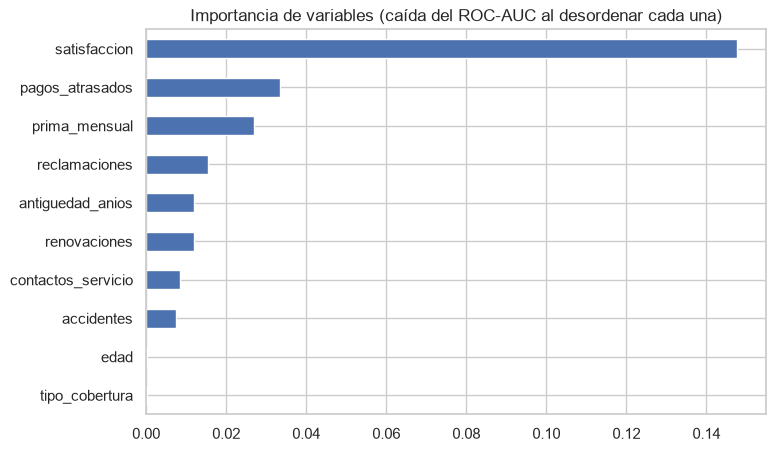

In [10]:
imp = permutation_importance(modelo_final, X_prueba, y_prueba, scoring="roc_auc", n_repeats=10, random_state=SEMILLA)
importancia = pd.Series(imp.importances_mean, index=COLS_X).sort_values()
importancia.plot(kind="barh", figsize=(8, 5), title="Importancia de variables (caída del ROC-AUC al desordenar cada una)")
plt.show()

## 11. Función de predicción para un cliente nuevo
Devuelve probabilidad, nivel de riesgo, acción sugerida y los factores que más empujan el riesgo de **ese** cliente.

In [11]:
REFERENCIA = {c: (X_ent[c].median() if c in COLS_NUM else X_ent[c].mode()[0]) for c in COLS_X}
ACCIONES = {"Alto": "Llamada personal del asesor en 48 horas y oferta de retención.",
            "Medio": "Enviar encuesta de satisfacción o beneficio en la renovación.",
            "Bajo": "Sin acción especial."}

def predecir_cliente(datos, modelo=modelo_final):
    cliente = pd.DataFrame([datos])[COLS_X]
    p = float(modelo.predict_proba(cliente)[0, 1])
    nivel = "Alto" if p >= 0.60 else "Medio" if p >= 0.35 else "Bajo"
    efectos = {}
    for c in COLS_X:
        alterno = cliente.copy(); alterno[c] = REFERENCIA[c]
        efectos[c] = p - float(modelo.predict_proba(alterno)[0, 1])
    efectos = pd.Series(efectos).sort_values(ascending=False)
    return {"probabilidad_abandono": round(p, 3), "nivel_riesgo": nivel, "accion": ACCIONES[nivel],
            "factores_que_aumentan_riesgo": efectos[efectos > 0.005].head(3).round(3).to_dict()}

ejemplo = dict(edad=29, antiguedad_anios=1, tipo_cobertura="Basica", prima_mensual=110.0, pagos_atrasados=3,
               accidentes=1, reclamaciones=2, satisfaccion=1, contactos_servicio=4, renovaciones=0)
predecir_cliente(ejemplo)

{'probabilidad_abandono': 0.971,
 'nivel_riesgo': 'Alto',
 'accion': 'Llamada personal del asesor en 48 horas y oferta de retención.',
 'factores_que_aumentan_riesgo': {'satisfaccion': 0.051,
  'pagos_atrasados': 0.044,
  'prima_mensual': 0.022}}

## 12. Guardar el modelo

In [12]:
joblib.dump(modelo_final, "modelo_churn_seguros.joblib")
print("Modelo guardado: modelo_churn_seguros.joblib")
# En Colab, descomenta las dos líneas siguientes para descargarlo a tu computadora:
# from google.colab import files
# files.download("modelo_churn_seguros.joblib")

Modelo guardado: modelo_churn_seguros.joblib


## 13. Conclusiones y limitaciones (útiles para el artículo)

**Resultados:** el modelo ordena a los clientes por riesgo de forma útil (ROC-AUC ≈ 0.75 con datos simulados). La satisfacción, los pagos atrasados y la prima mensual fueron las variables más influyentes.

**Valor para el negocio:** el modelo permite priorizar llamadas. El umbral de contacto se elige comparando el costo de contactar con el valor de retener, y no se deja en 0.50 por defecto.

**Limitaciones:**
- Los datos son simulados con una regla artificial; los resultados no se pueden generalizar a una aseguradora real.
- No se validó con datos de otro periodo (en una empresa real se entrena con el pasado y se prueba con el año siguiente).
- Las cifras de costo y éxito de retención son supuestos.
- Una probabilidad alta no garantiza que el cliente se irá.

**Trabajo futuro:** usar datos reales anonimizados, incorporar respuestas de encuestas reales, monitorear el modelo y reentrenarlo periódicamente.